# Phase 2 (random version): choose the subset

The 21,000 labelled photos in Japan, India and Czech are our **population**. We can't train on all of them on a laptop, so we draw a **plain random sample** of 2,000 photos per country. No weights, so the sample keeps the natural mix of the data.

In [1]:
import sys
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config

PER_COUNTRY = 2000
MERGE = {"D00": "D00", "D01": "D00", "D10": "D10", "D11": "D10", "D20": "D20", "D40": "D40"}  # D01/D11 are joint cracks
CLASSES = ["D00", "D10", "D20", "D40", "clean"]
COLORS = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444", "#9ca3af"]
NAMES = {"D00": "D00 · Longitudinal crack (along the road)", "D10": "D10 · Transverse crack (across the road)",
         "D20": "D20 · Alligator crack (web of cracks)", "D40": "D40 · Pothole",
         "clean": "clean · none of our 4 classes in the photo"}
LEGEND = [plt.Rectangle((0, 0), 1, 1, color=col, label=NAMES[k]) for k, col in zip(CLASSES, COLORS)]

## 1. The population: which classes does each photo contain?

In [2]:
rows = []
for country in config.COUNTRIES:
    for path in (config.RAW / country / "train" / "annotations" / "xmls").glob("*.xml"):
        found = [o.find("name").text for o in ET.parse(path).getroot().findall("object")]
        ours = {MERGE[c] for c in found if c in MERGE}
        rows.append({"image_id": path.stem, "country": country, **{k: k in ours for k in CLASSES[:4]}, "clean": not ours})

photos = pd.DataFrame(rows)
per_country = photos.groupby("country")[CLASSES].sum().loc[config.COUNTRIES]
per_country["total photos"] = photos.groupby("country").size()
per_country

,D00,D10,D20,D40,clean,total photos
country,,,,,,
Japan,2797,2240,4714,1390,2606,10506
India,1217,95,1758,1530,4388,7706
Czech,764,300,129,154,1757,2829


## 2. Random sample: 2,000 photos per country, seed 42

In [3]:
subset = photos.groupby("country", group_keys=False).sample(n=PER_COUNTRY, random_state=config.SEED)
print(len(subset), "photos picked")
subset.groupby("country").size()

6000 photos picked


country
Czech    2000
India    2000
Japan    2000
dtype: int64

## 3. Does the sample look like the population? (share of photos containing each class)

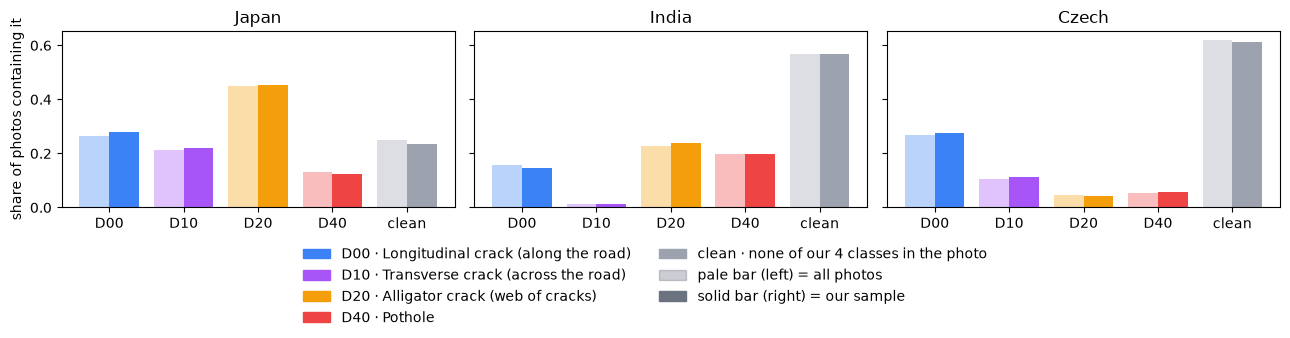

In [4]:
before = photos.groupby("country")[CLASSES].mean().loc[config.COUNTRIES]
after = subset.groupby("country")[CLASSES].mean().loc[config.COUNTRIES]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, c in zip(axes, config.COUNTRIES):
    x = np.arange(len(CLASSES))
    ax.bar(x - 0.2, before.loc[c], 0.4, color=COLORS, alpha=0.35)
    ax.bar(x + 0.2, after.loc[c], 0.4, color=COLORS)
    ax.set_xticks(x, CLASSES)
    ax.set_title(c)
axes[0].set_ylabel("share of photos containing it")
fig.legend(handles=LEGEND + [plt.Rectangle((0, 0), 1, 1, color="#6b7280", alpha=0.35, label="pale bar (left) = all photos"),
                             plt.Rectangle((0, 0), 1, 1, color="#6b7280", label="solid bar (right) = our sample")],
           loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.26, 1, 1))
plt.show()

## 4. Box counts in the sample (the guide wants at least about 1,500 per class)

In [5]:
box_rows = []
for r in subset.itertuples():
    path = config.RAW / r.country / "train" / "annotations" / "xmls" / f"{r.image_id}.xml"
    for o in ET.parse(path).getroot().findall("object"):
        if o.find("name").text in MERGE:
            box_rows.append({"country": r.country, "cls": MERGE[o.find("name").text]})

counts = pd.DataFrame(box_rows).value_counts(["country", "cls"]).unstack(fill_value=0)[CLASSES[:4]].loc[config.COUNTRIES]
counts.loc["TOTAL"] = counts.sum()
counts

cls,D00,D10,D20,D40
country,,,,
Japan,813,744,1173,407
India,414,36,551,802
Czech,724,302,112,150
TOTAL,1951,1082,1836,1359


In [6]:
OUT = config.PROCESSED / "02_subset"
OUT.mkdir(parents=True, exist_ok=True)
subset[["image_id", "country"]].sort_values("image_id").to_csv(OUT / "subset_images_random.csv", index=False)
print("saved", OUT / "subset_images_random.csv")

saved /Users/user/Documents/Y4/ML/road-damage-classifier/backend/data/processed/02_subset/subset_images_random.csv


## Decision

**Population:** all labelled photos in Japan, India and Czech (21,041). **Sample:** 2,000 random photos per country = 6,000 photos (about 240,000 squares), seed 42, no weights.

**Why these countries:** they are shot from a driver's view with the same damage codes, and between them they have all four classes. Skipped: Norway (huge, wide photos), the US, and China_Drone (shot from above).

**Why 2,000 each:** all 21,000 photos would give about 840,000 squares, too slow for an SVM on a laptop.

**Why random:** the sample keeps the natural mix of the data, so validation and test scores reflect real roads. The chart confirms each country's sample looks like its population. Balancing happens later, on the training split only.

| Boxes in the sample | D00 | D10 | D20 | D40 |
|---|---|---|---|---|
| Total | 1,951 | 1,082 | 1,836 | 1,359 |

**Known limits:**
- D10 (1,082) and D40 (1,359) are under the guide's 1,500-box minimum. D10 is the rarest class, and India has only 36 D10 boxes in its sample.
- If the model struggles on D10 or D40, first raise `PER_COUNTRY` (about 3,000 would give roughly 1,600 D10 boxes) before adding any weights.

The photo list is saved as `data/processed/02_subset/subset_images_random.csv`.

## Decision

**Population:** all labelled photos in Japan, India and Czech (21,041). **Sample:** 2,000 random photos per country = 6,000 photos (about 240,000 squares), seed 42, no weights.

**Why these countries:** they are shot from a driver's view with the same damage codes, and between them they have all four classes. Skipped: Norway (huge, wide photos), the US, and China_Drone (shot from above).

**Why 2,000 each:** all 21,000 photos would give about 840,000 squares, too slow for an SVM on a laptop.

**Why random:** the sample keeps the natural mix of the data, so validation and test scores reflect real roads. The chart confirms each country's sample looks like its population. Balancing happens later, on the training split only.

| Boxes in the sample | D00 | D10 | D20 | D40 |
|---|---|---|---|---|
| Total | 1,951 | 1,082 | 1,836 | 1,359 |

**Known limits:**
- D10 (1,082) and D40 (1,359) are under the guide's 1,500-box minimum. D10 is the rarest class, and India has only 36 D10 boxes in its sample.
- If the model struggles on D10 or D40, first raise `PER_COUNTRY` (about 3,000 would give roughly 1,600 D10 boxes) before adding any weights.

The photo list is saved as `data/processed/02_subset/subset_images_random.csv`.